Here we import some libraries that we will need to process images, do maths, and to visualise results.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torchvision
import torch
from tqdm import tqdm
from torchvision import datasets, transforms
%matplotlib inline

Helper functions:

In [2]:
class Visualizer():
    def __init__(self, num_rows=1, num_cols=1, figsize=(5,5), axis_off=True, title='', tight=False, cm=None):
        fig, self.axs = plt.subplots(num_rows, num_cols, figsize=figsize, squeeze=False)
        # remove ticks
        if axis_off:
          plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
        # set colormap
        if cm is not None:
            plt.set_cmap(cm)
        # set supertitle
        fig.suptitle(title)
        if tight:
            fig.subplots_adjust(top=0.88)

    def add_image_subplot(self, i, j, image, normalize=False, title_str=''):
        if normalize:
            image = self.normalize_image(image)
        if len(image.shape) == 3:
            #BGR -> RGB
            image = image[:, :, ::-1]
        self.axs[i, j].imshow(image)
        self.axs[i, j].set_title(title_str)

    def add_stem_subplot(self, i, j, x, y, title_str=''):
        self.axs[i, j].stem(x, y)
        self.axs[i, j].set_title(title_str)

    def add_subplot(self, i, j, data, title_str=''):
        self.axs[i, j].plot(data)
        self.axs[i, j].set_title(title_str)

    def add_bar_subplot(self, i, j, x, y, title_str=''):
        self.axs[i, j].bar(x, y)
        self.axs[i, j].set_title(title_str)

    @staticmethod
    def normalize_image(image):
        img = np.float64(image) - np.min(image)
        img /= np.max(img)
        return img

## Image Classification

Let us train a linear classifier on the CIFAR10 dataset.
First, we will load the dataset and show some sample images. The convention in pytorch is to store images in a tensor of shape $C\times H \times W$, where $C=3$ is the number of channels and $H$ and $W$ are the height and width of the image. For training, we typically load mini-batches of size $N$, which adds another dimension $N \times C \times H \times W$ to our data. The image visualiser expects data in the format $H \times W \times C$ so you will find some shuffling of dimension in the code below. Additionally, OpenCV prefers processing images in BGR format, while pytorch uses RGB so we also need to reverse the order of the $C$ dimension.

100%|██████████| 170M/170M [32:00<00:00, 88.8kB/s]   


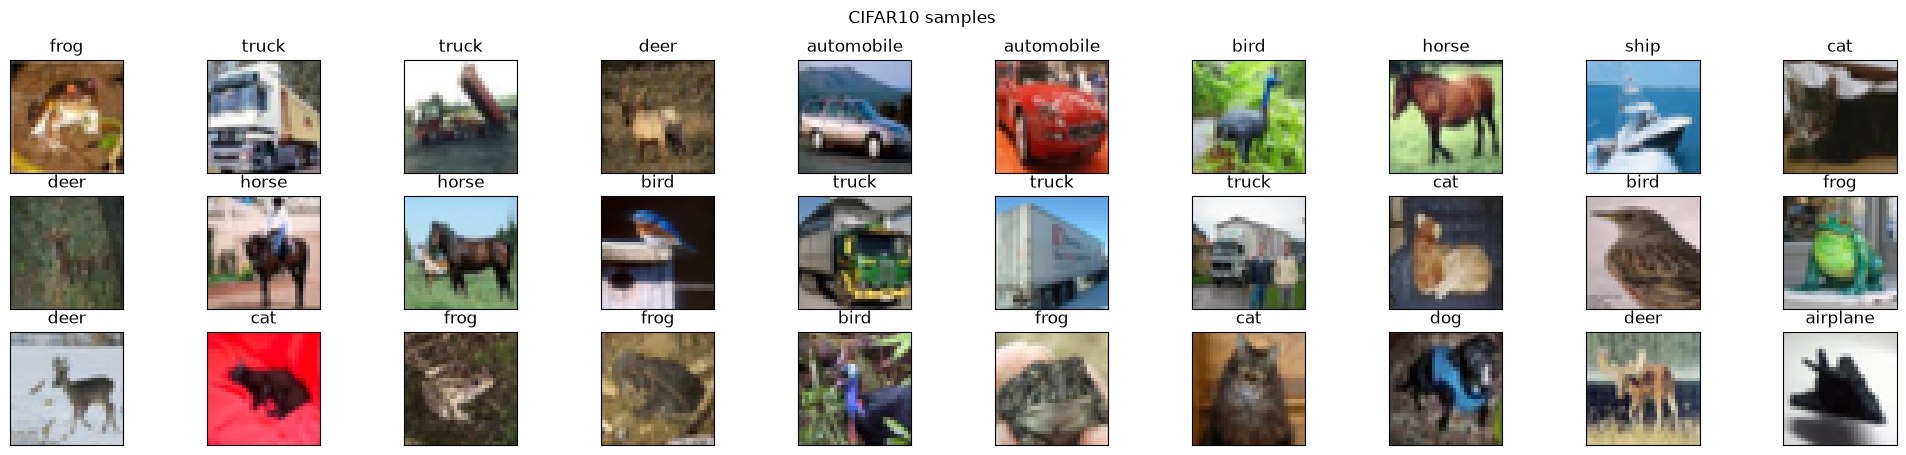

In [3]:
# get cifar10 dataset
transform = transforms.Compose([transforms.ToTensor()]) # also scales from 0 to 255
train_dataset = datasets.CIFAR10('../data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10('../data', train=False, download=True, transform=transform)


# samples from cifar10 dataset
vis = Visualizer(3, 10, figsize=(25,5), title='CIFAR10 samples')
for i in range(30):
    image = train_dataset[i][0].permute(1, 2, 0).numpy()[:,:,::-1]  # permute changes the ordering of tensor dimension, last part changes the order of channel
    vis.add_image_subplot(i // 10, i % 10, image, title_str=train_dataset.classes[train_dataset[i][1]])

While we can "train" a linear classifier by solving a linear system analytically, we will now do it with gradient descent to familiarise ourselves with the concepts of training. Training typically happens in epochs, where one epoch is a full loop over the training set. Familiarise yourself with the training code below. Answer the following questions:

* What is the purpose of `optimizer.zero_grad()`?
    * It clears the accumulated gradients from previous iterations
* What is `citerion`?
    * loss function used to measure the difference between model's prediction and the ground truth labels. (cross entropy loss)
* How do we determine which class the model predicts?
    * we select the class with the highest output score using argmax
* How many parameters does our model have?
    * 3 x 32 x 32 = 3072 input features, 10 bias so total of 30730
* What accuracy would we expect for a model that is randomly initialised?
    * p = 1/10 = 0.1


In [4]:
# create dataloaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)

def evaluate(model, test_loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            output = model(data)
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

    accuracy = 100. * correct / len(test_loader.dataset)
    return accuracy

def train(model, train_loader, test_loader, criterion, optimizer, num_epochs=10):
    train_losses = []
    test_accuracies = []
    for epoch in range(num_epochs):
        model.train()
        for data, target in tqdm(train_loader):
            optimizer.zero_grad()
            output = model(data)    # forward pass through the network to calculate class scores
            loss = criterion(output, target)    # compares predicted score with correct labels
            loss.backward() # backpropagation to find gradient of loss with respect to model parameters
            optimizer.step()    # update parameters using calculated gradients
            train_losses.append(loss.item())

        test_acc = evaluate(model, test_loader)
        test_accuracies.append(test_acc)
        print(f'Epoch {epoch+1}/{num_epochs}, Test accuracy: {test_acc:.2f}%')

    return train_losses, test_accuracies

class LinearModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = torch.nn.Linear(3*32*32, 10)  # flatten into vector and then y = Wx+b

    def forward(self, x):
        x = x.view(-1, 3*32*32)
        x = self.fc(x)
        return x

model = LinearModel()
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses, test_accuracies = train(model, train_loader, test_loader, criterion, optimizer, num_epochs=5)

100%|██████████| 391/391 [00:04<00:00, 82.47it/s] 


Epoch 1/5, Test accuracy: 35.94%


100%|██████████| 391/391 [00:03<00:00, 125.20it/s]


Epoch 2/5, Test accuracy: 36.88%


100%|██████████| 391/391 [00:03<00:00, 125.55it/s]


Epoch 3/5, Test accuracy: 37.17%


100%|██████████| 391/391 [00:03<00:00, 127.90it/s]


Epoch 4/5, Test accuracy: 37.71%


100%|██████████| 391/391 [00:03<00:00, 127.17it/s]


Epoch 5/5, Test accuracy: 37.94%


Now that the model is trained, visualise the weights of the linear layer. There are $3\cdot 32 \cdot 32$ weights for each class which you can visualise simply as an image. What do you see? Why does it look like that?

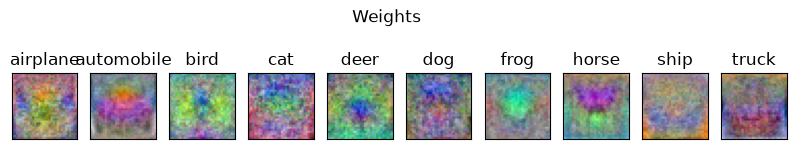

In [6]:
vis = Visualizer(1, 10, figsize=(10,2), title='Weights')
for i in range(10):
    weights = 0

    # TODO: visualise weights
    weights = model.fc.weight[i].detach().numpy()
    weights = weights.reshape(3, 32, 32)
    weights = np.transpose(weights, (1, 2, 0))

    vis.add_image_subplot(0, i, weights, title_str=train_dataset.classes[i], normalize=True)

We will now train a small CNN. It consists of
* Convolution: size $3\times 3$, number of channels $3$ (RGB), number of filters: $16$, padding: $1$ on all sides
* ReLU
* MaxPooling: size $2\times 2$, stride: $2$
* Fully Connected layer: $4096 \times 10$

In [8]:
class MiniCNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = torch.nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        self.fc = torch.nn.Linear(4096, 10)

    def forward(self, x):
        x = torch.nn.functional.relu(self.conv1(x))
        x = torch.nn.functional.max_pool2d(x, kernel_size=2, stride=2)
        x = x.view(-1, 4096)
        x = self.fc(x)
        return x

model = MiniCNN()
# TODO: train the model

model = MiniCNN()

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses, test_accuracies = train(model, train_loader, test_loader, criterion, optimizer, num_epochs=10)


100%|██████████| 391/391 [00:06<00:00, 62.36it/s]


Epoch 1/10, Test accuracy: 48.46%


100%|██████████| 391/391 [00:05<00:00, 66.81it/s]


Epoch 2/10, Test accuracy: 53.17%


100%|██████████| 391/391 [00:07<00:00, 51.21it/s]


Epoch 3/10, Test accuracy: 54.31%


... (10 outputs left out)

100%|██████████| 391/391 [00:07<00:00, 50.30it/s]


Epoch 9/10, Test accuracy: 59.31%


100%|██████████| 391/391 [00:05<00:00, 75.86it/s]


Epoch 10/10, Test accuracy: 59.88%


This model should achieve around 57% accuracy on the test set (with the default settings for batch size, learning rate, and number of epochs).

Answer the following questions:
* Why do we need to define the convolution and FC layer in the constructor (`__init__()`) of the model, but ReLU and max_pool are simply used in the forward pass?
    * Convolution and fully connect layer have learnable parameters, whereas ReLU and max pooling do not. We can put ReLU and max pooling inside __init__() too.
* How do we know that the fully connected layer needs to be of size $4096 \times 10$?
    * Input: 3 x 32 x 32
    * Convolution: 16 x 32 x 32
    * ReLU: 16 x 32 x 32
    * Max pooling: 16 x 16 x 16
    * Flatten: 16 x 16 x 16 = 4096
    * FC layer: 10 classes x 4096

Then, expand the model with a second set of convolution ($3\times 3$, $32$ filters, padding $1$), ReLU, max_pool ($2\times 2$, stride $2$). You will need to also adjust the size of the FC layer accordingly. Confirm that this improves the accuracy.

In [10]:
class MiniCNN2(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: define the model
        self.conv1 = torch.nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        self.conv2 = torch.nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.fc = torch.nn.Linear(2048, 10)


    def forward(self, x):
        # TODO: define the forward pass
        x = torch.nn.functional.relu(self.conv1(x))
        x = torch.nn.functional.max_pool2d(x, kernel_size=2, stride=2)
        x = torch.nn.functional.relu(self.conv2(x))
        x = torch.nn.functional.max_pool2d(x, kernel_size=2, stride=2)

        x = x.view(-1, 2048)
        x = self.fc(x)
        return x

model = MiniCNN2()
# TODO: train the model

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_losses, test_accuracies = train(model, train_loader, test_loader, criterion, optimizer, num_epochs=10)

100%|██████████| 391/391 [00:07<00:00, 53.23it/s]


Epoch 1/10, Test accuracy: 51.26%


100%|██████████| 391/391 [00:06<00:00, 60.18it/s]


Epoch 2/10, Test accuracy: 55.32%


100%|██████████| 391/391 [00:06<00:00, 59.69it/s]


Epoch 3/10, Test accuracy: 58.11%


... (10 outputs left out)

100%|██████████| 391/391 [00:06<00:00, 59.56it/s]


Epoch 9/10, Test accuracy: 65.46%


100%|██████████| 391/391 [00:06<00:00, 59.38it/s]


Epoch 10/10, Test accuracy: 66.41%


### Optional Task - Be a hero
You have now several options that might improve the performance:
* Change the architecture further.
* Train longer.
* Change other hyper parameters: batch size, learning rate, kernel sizes, number of filters, activation functions, etc.
* Data augmentations such as left-right flipping (see `transform` in the beginning).

Try to find a combination that gets better accuracy than `MiniCNN2` (at least 63%). Do not change the test set! (State-of-the-art models get around 95% ;) )
Hint: if you are considering to tinker with this for a while: switch to hardware acceleration (GPU) - Edit->Notebook settings. Then change the code to move the model and tensors to the GPU `.to("cuda")` before starting to train. You will need to move each batch to the device too. Move predictions back to the CPU `.cpu()` so that they do not accumulate memory.